# Loading the Chile macro-fiscal model into ModelFlow

The deterministic macro-fiscal / pension model, ported from Stata.

**Ported from** `model_macrofiscal_deterministic.do` (Stata)
**Input data** `bbdd_v3.dta` — annual 1996–2075, history through 2024
**Checked against** `Data_efter.xlsx` — the Stata dataset *after* the do-file has run
**Earlier version** `../pensionsmodel/fromzip/chile_macrofiscal_modelflow.ipynb` (stochastic do-file) and
its companion `ANALYSIS_stata_to_modelflow.md`

---

## Summary

This notebook **loads the model into ModelFlow**: it writes the Stata do-file's equations as a
ModelFlow model, block by block, estimates the three equations the do-file estimates, and
assembles everything into one model, `mchile`. To show that the model is loaded correctly, it is
solved 2025–2070 from the raw data and compared with Stata's own result.

- **The model reproduces Stata.** Every endogenous variable that is also in `Data_efter.xlsx`
  agrees to Stata's storage precision, and the estimated coefficients match the do-file's.
  The only visible gaps are four series that the Excel export rounded to two significant digits.
- **Eight blocks:** demography and labour supply, two-sector production, prices and the external
  block, the sovereign spread, ageing-driven expenditure, saving and the consumption rate,
  revenue and debt, and reporting.
- **The model is recursive.** Every feedback is lagged, so it solves in one pass.

:::{figure} graph/stata_vs_modelflow.png
:alt: Debt, primary spending, revenue and the spread, Stata against ModelFlow, 2010-2070
:width: 100%

Stata (thick line) against ModelFlow (dashed), 2010–2070. The figure is made at the end of the
notebook.
:::

## Purpose

This notebook is a **reproduction check**, not a scenario tool. The model is written to follow the
deterministic do-file line by line with the settings it ships with (`ret_age = 0`, `health_old = 1`,
`school_age = 0`), solved 2025–2070 from the raw data, and every variable that also exists in
`Data_efter.xlsx` is compared with Stata's result.

## What differs from the stochastic do-file (and the earlier notebook)

| Area | Stochastic file / earlier notebook | Deterministic file / this notebook |
|---|---|---|
| Uncertainty | 2000-draw Monte Carlo, nine shocks | none |
| `PENSION_EL` | 0.36 | **0.48** |
| `PEN_RATIO` | `N_TOT_PEN / LAB_MAR` | **`N_TOT_PEN / N_TOT`** |
| OECD pension step | +1.2 pp in 2025, elasticity from 2026 | +1.2 pp in 2025, **flat 2026–2030**, elasticity from 2031 |
| Health | trend × `exp(ν)`, AR(1) residual | plain elasticity recursion from the 2024 actual |
| Consumption-rate constant | estimated `C(1)` kept | sample mean **+ 0.015**, as in the do-file |
| Scenario switches | `D_RET*`, `D_HEALTH_OLD`, `D_SCHOOL_AGE`, `P_CHANGE` | left out — only the shipped settings are reproduced |

## How this notebook is organised

As in the earlier notebook, each model block is one `%%Makemymodel chile segment=<name>` cell. The
body is Markdown; the **equations are the lines beginning with `>`**, and `>>` continues the line
above. `%Makemymodel chile` at the end reassembles the segments into one `Makemodel`.

Variable names are the Stata names in upper case (`_u_tot` becomes `U_TOT`), so the comparison with
`Data_efter.xlsx` is a direct name match.

In [1]:
from modelclass import model
import modeljupytermagic          # registers %%Makemymodel

import pandas as pd
import numpy as np
import warnings
warnings.simplefilter('ignore', pd.errors.PerformanceWarning)

model.widescreen()
model.scroll_off()

FIRST, LAST = 2025, 2070          # demography stops in 2070

<IPython.core.display.Javascript object>

---
## Data

`bbdd_v3.dta` is not in this folder; it is read from the earlier one. `Data_efter.xlsx` is only
used at the end, for the comparison.

In [2]:
BB = pd.read_stata('../pensionsmodel/fromzip/bbdd_v3.dta').set_index('period')
BB.index = BB.index.astype(int)

STATA = pd.read_excel('Data_efter.xlsx').set_index('period')
STATA.index = STATA.index.astype(int)

print(f'bbdd_v3      {BB.shape[1]:4d} variables {BB.index.min()}-{BB.index.max()}')
print(f'Data_efter   {STATA.shape[1]:4d} variables {STATA.index.min()}-{STATA.index.max()}')

bbdd_v3        71 variables 1996-2075
Data_efter    145 variables 1996-2075


---
## The estimation dataframe

Two of the do-file's regressions are estimated in place with `<est=ols>`:

| Stata | Model equation | Tag |
|---|---|---|
| `regress ln_Rstar L.ln_Rstar, nocons` | `LN_RSTAR` | `<est=ols>` |
| `regress ln_pcopper_real L.ln_pcopper_real, nocons` | `LN_PCOPPER_REAL` | `<est=ols>` |
| `regress ytilde_cons_rate pop_growth age_speed prime_age_sav` (1997–2019) | `CONS_RATE_EQ` | `<est=ols,smpl=1997 2019>` |

The other regressions in the do-file (`ln_tfp18`, `ln_f_c`, `d_embi`, `d_embi_r`) produce scalars
the deterministic run never uses, so they are left out.

**The consumption-rate equation is estimated in one piece, imposed and estimated coefficients
together.** Stata builds a residual `ytilde_cons_rate` by subtracting the three imposed IMF terms
from `cons_rate`, regresses it on the three demographic flows with a constant, throws the constant
away, and projects with the 1997–2019 mean `+ 0.015`. Here the imposed terms are simply written
into the equation; `Estimate_ols` moves every term without a coefficient to the left-hand side
before the fit, which is the same regression.

Every regressor is a **deviation from its 1997–2019 mean**, so the intercept `C(1)` is exactly the
sample mean of `cons_rate` (the do-file's `cte_cons_rate`). The `+0.015` is carried by
`CONS_RATE_ADJ`, and `DAMP_*` are 1 here and 4 or 3 in projection.

In [3]:
est_df = pd.DataFrame(index=BB.index)

# external AR(1) regressands (do-file: ln_Rstar, ln_pcopper_real)
est_df['LN_RSTAR']        = np.log(1+BB.Rstar/100) - np.log(1+2.5/100)
est_df['LN_PCOPPER_REAL'] = np.log(BB.pcopper/BB.ipc_us) - np.log(4.38/205.60)

# consumption-rate block, benchmark definitions (ret_age = 0, health_old = 1)
old_ratio = BB.n_tot_o79 / BB.n_tot
est_df['LIFE_EXP']      = BB.life_exp
est_df['POP_GROWTH']    = np.log(BB.n_tot).diff()
est_df['AGE_SPEED']     = np.log(old_ratio).diff()
est_df['OLD_AGE_DEP']   = (BB.n_f_o59 + BB.n_m_o64) / (BB.n_f_1559 + BB.n_m_1564)
est_df['PRIME_AGE_SAV'] = (BB.n_tot_4064 - BB.n_f_o59 + BB.n_f_o64) / BB.n_tot

W = slice(1997, 2019)                     # do-file: period>1996 & period<2020
MEANS = dict(
    CTE_CONS_RATE    = BB.cons_rate.loc[W].mean(),
    OAD_MEAN         = est_df.OLD_AGE_DEP.loc[W].mean(),
    LIFEEXP_MEAN     = est_df.LIFE_EXP.loc[W].mean(),
    LIFEEXPOAD_MEAN  = (est_df.LIFE_EXP*est_df.OLD_AGE_DEP).loc[W].mean(),
    POPGROWTH_MEAN   = est_df.POP_GROWTH.loc[W].mean(),
    AGINGSPEED_MEAN  = est_df.AGE_SPEED.loc[W].mean(),
    PRIMESAVERS_MEAN = est_df.PRIME_AGE_SAV.loc[W].mean(),
)
for k, v in MEANS.items():
    est_df[k] = v
est_df['CONS_RATE_EQ'] = BB.cons_rate          # the regressand

for v in ['DAMP_OAD', 'DAMP_POP', 'DAMP_AGE', 'DAMP_PRIME', 'DAMP_LIFE', 'DAMP_LOAD']:
    est_df[v] = 1.0
est_df['CONS_RATE_ADJ'] = 0.0

est_df.loc[2015:2024].round(4)

,LN_RSTAR,LN_PCOPPER_REAL,LIFE_EXP,POP_GROWTH,AGE_SPEED,OLD_AGE_DEP,PRIME_AGE_SAV,CTE_CONS_RATE,OAD_MEAN,LIFEEXP_MEAN,...,AGINGSPEED_MEAN,PRIMESAVERS_MEAN,CONS_RATE_EQ,DAMP_OAD,DAMP_POP,DAMP_AGE,DAMP_PRIME,DAMP_LIFE,DAMP_LOAD,CONS_RATE_ADJ
period,,,,,,,,,,,,,,,,,,,,,
2015,-0.0036,-0.4280,79.900002,0.0115,0.0234,0.1994,0.2874,0.6662,0.1731,78.487,...,0.0298,0.2621,0.6711,1.0,1.0,1.0,1.0,1.0,1.0,0.0
2016,-0.0065,-0.2384,80.300003,0.0131,0.0228,0.2048,0.2879,0.6662,0.1731,78.487,...,0.0298,0.2621,0.6713,1.0,1.0,1.0,1.0,1.0,1.0,0.0
2017,-0.0017,-0.0768,80.500000,0.0147,0.0209,0.2102,0.2875,0.6662,0.1731,78.487,...,0.0298,0.2621,0.6820,1.0,1.0,1.0,1.0,1.0,1.0,0.0
2018,0.0040,-0.2107,80.800003,0.0158,0.0222,0.2161,0.2866,0.6662,0.1731,78.487,...,0.0298,0.2621,0.6811,1.0,1.0,1.0,1.0,1.0,1.0,0.0
2019,-0.0035,-0.2340,80.900002,0.0151,0.0287,0.2227,0.2859,0.6662,0.1731,78.487,...,0.0298,0.2621,0.6716,1.0,1.0,1.0,1.0,1.0,1.0,0.0
2020,-0.0158,0.0000,79.900002,0.0102,0.0313,0.2301,0.2863,0.6662,0.1731,78.487,...,0.0298,0.2621,0.6609,1.0,1.0,1.0,1.0,1.0,1.0,0.0
2021,-0.0104,0.1623,79.199997,0.0081,0.0278,0.2373,0.2873,0.6662,0.1731,78.487,...,0.0298,0.2621,0.7221,1.0,1.0,1.0,1.0,1.0,1.0,0.0
2022,0.0044,-0.0471,79.800003,0.0097,0.0234,0.2439,0.2882,0.6662,0.1731,78.487,...,0.0298,0.2621,0.7326,1.0,1.0,1.0,1.0,1.0,1.0,0.0
2023,0.0140,-0.0844,81.199997,0.0089,0.0314,0.2517,0.2889,0.6662,0.1731,78.487,...,0.0298,0.2621,0.6750,1.0,1.0,1.0,1.0,1.0,1.0,0.0


---
## Variable descriptions

Carried by `Makemodel` to the `model` object, where they label charts, tables and graphs.

In [4]:
var_description = {
# demography
'N_F_1559': 'Women aged 15-59', 'N_F_O59': 'Women aged 60+', 'N_M_1564': 'Men aged 15-64',
'N_M_O64': 'Men aged 65+', 'N_TOT': 'Total population', 'N_TOT_PEN': 'Population above pension age',
'N_TOT_024': 'Population aged 0-24', 'N_TOT_4064': 'Population aged 40-64',
'N_TOT_O79': 'Population aged 80+', 'LIFE_EXP': 'Life expectancy at birth, years',
'P_F_1559': 'Participation rate, women 15-59', 'P_F_O59': 'Participation rate, women 60+',
'P_M_1564': 'Participation rate, men 15-64', 'P_M_O64': 'Participation rate, men 65+',
# labour
'LAB_MAR': 'Labour force (participation-weighted cohorts)', 'H_YEAR': 'Contractual annual hours per worker',
'H_YEAR_ACT': 'Annual hours per worker adjusted for unemployment', 'U_TOT': 'Employment rate',
'A': 'Labour productivity index, 2010 = 1', 'D_A': 'Labour productivity growth, log change',
'LE2': 'Effective labour before re-basing', 'LE': 'Effective labour input',
'H_C': 'Effective labour, commodity sector', 'H_NC': 'Effective labour, non-commodity sector',
'OMEGA_C': 'Commodity share of effective labour',
# production
'TFP18': 'Total factor productivity, common to both sectors', 'F_C': 'Mineral resource input',
'PIBREAL_C': 'Real GDP, commodity', 'PIBREAL_NC': 'Real GDP, non-commodity', 'PIBREAL_TOT': 'Real GDP, total',
'FBKF_C': 'Investment, commodity', 'FBKF_NC': 'Investment, non-commodity',
'STOCK_K_C': 'Capital stock, commodity', 'STOCK_K_NC': 'Capital stock, non-commodity',
'ALPHA_C': 'Capital elasticity, commodity', 'BETA_C': 'Mineral resource elasticity, commodity',
'ALPHA_NC': 'Capital elasticity, non-commodity', 'DELTA': 'Depreciation rate',
'TINV_C': 'Trend investment ratio, commodity', 'TINV_NC': 'Trend investment ratio, non-commodity',
'MU_C': 'Cost-of-capital sensitivity, commodity', 'MU_NC': 'Cost-of-capital sensitivity, non-commodity',
'DLZ_AVG': 'TFP trend growth',
# prices
'IPC': 'CPI, Chile', 'IPC_US': 'CPI, United States', 'DIPC': 'CPI inflation Chile, percent',
'DIPC_US': 'CPI inflation US, percent', 'EXRATE': 'Exchange rate, pesos per dollar',
'DEF_C': 'GDP deflator, commodity', 'DEF_NC': 'GDP deflator, non-commodity',
'PIBNOM_C': 'Nominal GDP, commodity', 'PIBNOM_NC': 'Nominal GDP, non-commodity', 'PIBNOM_TOT': 'Nominal GDP, total',
'RSTAR': 'World real interest rate, percent', 'LN_RSTAR': 'World interest rate, log deviation from steady state',
'PCOPPER': 'Copper price, dollars per pound', 'LN_PCOPPER_REAL': 'Real copper price, log deviation from steady state',
'RSTAR_SS': 'World interest rate, steady state', 'PCOPPER_SS': 'Copper price, steady state',
# spread
'EMBI': 'Sovereign spread, basis points', 'EMBI_R': 'Spread net of the debt effect',
'MEAN_EMBI_R': 'Historical mean of EMBI_R', 'RHO_EMBI_R': 'Persistence of EMBI_R (imposed 0.99)',
'EMBI_SS': 'Spread, steady state', 'ELAST_EMBI_B_G': 'Spread response to debt', 'B_G_SS': 'Debt anchor',
# expenditure
'PEN_RATIO': 'Population above pension age per inhabitant', 'G_P_NOM_GDP': 'Pension spending, share of GDP',
'G_P_STEP': 'One-off pension step (OECD, 2025)', 'D_PEN_EL': 'Switch: pension elasticity active',
'PENSION_EL': 'Pension elasticity', 'OLD_RATIO': 'Share of population aged 80+',
'G_H_NOM_GDP': 'Health spending, share of GDP', 'HEALTH_EL': 'Health elasticity',
'SCHOOL_RATIO': 'Share of population aged 0-24', 'G_E_NOM_GDP': 'Education spending, share of GDP',
'EDUCATION_EL': 'Education elasticity', 'G_O_NOM_GDP': 'Other current spending, share of GDP',
'REDUC_G_O': 'Annual retention factor, other spending', 'G_NOM_GDP': 'Current primary spending, share of GDP',
# saving
'POP_GROWTH': 'Population growth, log change', 'AGE_SPEED': 'Ageing speed, log change in OLD_RATIO',
'OLD_AGE_DEP': 'Old-age dependency ratio', 'PRIME_AGE_SAV': 'Prime-age saver share',
'CONS_RATE_EQ': 'Consumption rate from the demographic equation',
'CONS_RATE': 'Consumption rate',
'CONS_RATE_ADJ': 'Add-on to the consumption-rate constant (0.015 in projection)',
'ROL_OAD': 'Contribution of old-age dependency to the consumption rate',
'ROL_LIFEEXP': 'Contribution of life expectancy to the consumption rate',
'ROL_LIFEEXPOAD': 'Contribution of the life expectancy interaction to the consumption rate',
# fiscal
'T_C': 'Tax rate, commodity GDP', 'T2_NC': 'Non-VAT tax rate, non-commodity GDP', 'T_IVA': 'VAT rate',
'T_NC': 'Total tax rate, non-commodity GDP', 'TAU_C': 'Target tax rate, commodity',
'TAU2_NC': 'Target non-VAT rate', 'TAU_CONS': 'Target VAT rate',
'INV_G': 'Public investment, share of GDP', 'DK_G': 'Capital transfers, share of GDP',
'A_G': 'Government assets, share of GDP', 'SELL_K_G': 'Sales of capital, share of GDP',
'O_G': 'Other outlays, share of GDP', 'G': 'Current primary spending, share of GDP',
'RA_G': 'Return on government assets, percent', 'RB_G': 'Interest rate on government debt, percent',
'B_G': 'Gross government debt, share of GDP',
# reporting
'REV_C': 'Mining revenue, share of GDP', 'REV_NC': 'Non-mining revenue, share of GDP',
'REV_TOT': 'Total revenue, share of GDP', 'G_TOT': 'Total spending, share of GDP',
'D_PIBREAL_TOT': 'Real GDP growth, percent', 'D_LE': 'Effective labour growth, percent',
'D_LAB_MAR': 'Labour force growth, percent',
}
print(f'{len(var_description)} variables have a description')

113 variables have a description


---
# The model

Eight blocks. Read the prose; the `>` lines are the model.

In [5]:
%%Makemymodel chile segment=demography

## Block 1 — Demography and labour supply

Population cohorts `N_*` are exogenous projections in `bbdd_v3.dta`. Participation rates are the
2022–2024 averages held from 2025 (do-file lines 74–83); they are set in the data. With the benchmark
retirement age the labour force is women 15–59 and 60+ plus men 15–64 and 65+.

Weekly hours are held at the 2024 value and the employment rate jumps to 0.95 in 2025. Productivity
`A` is 1 in 2010 and grows at `D_A`, which is 1.2259 % a year from 2025. `LE` is re-based on the
growth of `LE2`, so the 2024 level of historical `Le` is kept.

> LAB_MAR    = P_F_1559*N_F_1559 + P_F_O59*N_F_O59 + P_M_1564*N_M_1564 + P_M_O64*N_M_O64

> H_YEAR     = H_YEAR(-1)
> H_YEAR_ACT = H_YEAR * U_TOT
> A          = A(-1) * EXP(D_A)
> LE2        = A * H_YEAR_ACT * LAB_MAR
> LE         = LE(-1) * LE2/LE2(-1)

## Block 1 — Demography and labour supply

Population cohorts `N_*` are exogenous projections in `bbdd_v3.dta`. Participation rates are the
2022–2024 averages held from 2025 (do-file lines 74–83); they are set in the data. With the benchmark
retirement age the labour force is women 15–59 and 60+ plus men 15–64 and 65+.

Weekly hours are held at the 2024 value and the employment rate jumps to 0.95 in 2025. Productivity
`A` is 1 in 2010 and grows at `D_A`, which is 1.2259 % a year from 2025. `LE` is re-based on the
growth of `LE2`, so the 2024 level of historical `Le` is kept.

```text
> LAB_MAR    = P_F_1559*N_F_1559 + P_F_O59*N_F_O59 + P_M_1564*N_M_1564 + P_M_O64*N_M_O64
```

```text
> H_YEAR     = H_YEAR(-1)
> H_YEAR_ACT = H_YEAR * U_TOT
> A          = A(-1) * EXP(D_A)
> LE2        = A * H_YEAR_ACT * LAB_MAR
> LE         = LE(-1) * LE2/LE2(-1)
```

In [6]:
%%Makemymodel chile segment=production

## Block 2 — Two-sector production

Unchanged from the stochastic file, without shocks. Both sectors share `TFP18`, which is held
constant (`DLZ_AVG = 0`). `F_C` grows with `LE` to keep the two sectors on a balanced growth path.
Production is written in growth-rate form, so levels are anchored at 2024. Capital enters with
one- and two-period lags, and investment responds to last year's `RSTAR` and `EMBI`.

> H_C   =    OMEGA_C  * LE
> H_NC  = (1-OMEGA_C) * LE

> TFP18 = TFP18(-1) * EXP(DLZ_AVG)
> F_C   = F_C(-1) * LE/LE(-1)

> PIBREAL_C  = PIBREAL_C(-1) * EXP( LOG(TFP18/TFP18(-1))
>>             + ALPHA_C            * LOG(STOCK_K_C(-1)/STOCK_K_C(-2))
>>             + (1-ALPHA_C-BETA_C) * LOG(H_C/H_C(-1))
>>             + BETA_C             * LOG(F_C/F_C(-1)) )

> PIBREAL_NC = PIBREAL_NC(-1) * EXP( LOG(TFP18/TFP18(-1))
>>             + ALPHA_NC     * LOG(STOCK_K_NC(-1)/STOCK_K_NC(-2))
>>             + (1-ALPHA_NC) * LOG(H_NC/H_NC(-1)) )

> FBKF_C  = PIBREAL_C  * (TINV_C  + MU_C *(RSTAR(-1)-RSTAR_SS + EMBI(-1)/100 - EMBI_SS/100))
> FBKF_NC = PIBREAL_NC * (TINV_NC + MU_NC*(RSTAR(-1)-RSTAR_SS + EMBI(-1)/100 - EMBI_SS/100))

> STOCK_K_C  = STOCK_K_C(-1) *(1-DELTA) + FBKF_C
> STOCK_K_NC = STOCK_K_NC(-1)*(1-DELTA) + FBKF_NC

> PIBREAL_TOT = PIBREAL_C + PIBREAL_NC

## Block 2 — Two-sector production

Unchanged from the stochastic file, without shocks. Both sectors share `TFP18`, which is held
constant (`DLZ_AVG = 0`). `F_C` grows with `LE` to keep the two sectors on a balanced growth path.
Production is written in growth-rate form, so levels are anchored at 2024. Capital enters with
one- and two-period lags, and investment responds to last year's `RSTAR` and `EMBI`.

```text
> H_C   =    OMEGA_C  * LE
> H_NC  = (1-OMEGA_C) * LE
```

```text
> TFP18 = TFP18(-1) * EXP(DLZ_AVG)
> F_C   = F_C(-1) * LE/LE(-1)
```

```text
> PIBREAL_C  = PIBREAL_C(-1) * EXP( LOG(TFP18/TFP18(-1))
>>             + ALPHA_C            * LOG(STOCK_K_C(-1)/STOCK_K_C(-2))
>>             + (1-ALPHA_C-BETA_C) * LOG(H_C/H_C(-1))
>>             + BETA_C             * LOG(F_C/F_C(-1)) )
```

```text
> PIBREAL_NC = PIBREAL_NC(-1) * EXP( LOG(TFP18/TFP18(-1))
>>             + ALPHA_NC     * LOG(STOCK_K_NC(-1)/STOCK_K_NC(-2))
>>             + (1-ALPHA_NC) * LOG(H_NC/H_NC(-1)) )
```

```text
> FBKF_C  = PIBREAL_C  * (TINV_C  + MU_C *(RSTAR(-1)-RSTAR_SS + EMBI(-1)/100 - EMBI_SS/100))
> FBKF_NC = PIBREAL_NC * (TINV_NC + MU_NC*(RSTAR(-1)-RSTAR_SS + EMBI(-1)/100 - EMBI_SS/100))
```

```text
> STOCK_K_C  = STOCK_K_C(-1) *(1-DELTA) + FBKF_C
> STOCK_K_NC = STOCK_K_NC(-1)*(1-DELTA) + FBKF_NC
```

```text
> PIBREAL_TOT = PIBREAL_C + PIBREAL_NC
```

In [7]:
%%Makemymodel chile segment=prices input_df=est_df smpl=(1997,2024)

## Block 3 — Prices, external block, nominal GDP

Inflation paths are set in the data: Chile 4.23 / 3.60 / 3.0 and the US 2.69 / 2.35 / 2.0 for
2025 / 2026 / 2027 onwards. The world interest rate and the real copper price decay towards their
steady states as AR(1) processes. The two persistence parameters are estimated in place, as Stata's
`regress …, noconstant`. The exchange rate follows relative PPP; the commodity deflator follows the
copper price in pesos.

> IPC_US = IPC_US(-1) * (1 + DIPC_US/100)
> IPC    = IPC(-1)    * (1 + DIPC/100)

> <est=ols> LN_RSTAR = C(1)*LN_RSTAR(-1)
> RSTAR = 100*EXP(LN_RSTAR + LOG(1+RSTAR_SS/100)) - 100

> <est=ols> LN_PCOPPER_REAL = C(1)*LN_PCOPPER_REAL(-1)
> PCOPPER = EXP(LN_PCOPPER_REAL + LOG(PCOPPER_SS/205.60)) * IPC_US

> EXRATE = EXRATE(-1) * (IPC/IPC(-1)) / (IPC_US/IPC_US(-1))
> DEF_C  = DEF_C(-1)  * (EXRATE/EXRATE(-1)) * (PCOPPER/PCOPPER(-1))
> DEF_NC = DEF_NC(-1) * (IPC/IPC(-1))

> PIBNOM_C   = DEF_C  * PIBREAL_C
> PIBNOM_NC  = DEF_NC * PIBREAL_NC
> PIBNOM_TOT = PIBNOM_C + PIBNOM_NC

## Block 3 — Prices, external block, nominal GDP

Inflation paths are set in the data: Chile 4.23 / 3.60 / 3.0 and the US 2.69 / 2.35 / 2.0 for
2025 / 2026 / 2027 onwards. The world interest rate and the real copper price decay towards their
steady states as AR(1) processes. The two persistence parameters are estimated in place, as Stata's
`regress …, noconstant`. The exchange rate follows relative PPP; the commodity deflator follows the
copper price in pesos.

```text
> IPC_US = IPC_US(-1) * (1 + DIPC_US/100)
> IPC    = IPC(-1)    * (1 + DIPC/100)
```

```text
> <est=ols> LN_RSTAR = C(1)*LN_RSTAR(-1)
```

**Estimation output**

| Item | Value |
|:--|:--|
| Estimator | ols |
| Requested sample | (1997, 2024) |
| Effective sample | (1997, 2024) |
| Original equation | LN_RSTAR = C(1)*LN_RSTAR(-1) |
| Estimated equation | LN_RSTAR = (0.8726796248)*LN_RSTAR(-1) |
| aic | -204.2178846 |
| bic | -202.88568 |
| R-squared | 0.8704337332 |
| Adj. R-squared | 0.8656349826 |

| Parameter | Estimate | t-stat |
|:--|--:|--:|
| C__1 | 0.8726796248 | 13.468 |
```text
> RSTAR = 100*EXP(LN_RSTAR + LOG(1+RSTAR_SS/100)) - 100
```

```text
> <est=ols> LN_PCOPPER_REAL = C(1)*LN_PCOPPER_REAL(-1)
```

**Estimation output**

| Item | Value |
|:--|:--|
| Estimator | ols |
| Requested sample | (1997, 2024) |
| Effective sample | (1997, 2024) |
| Original equation | LN_PCOPPER_REAL = C(1)*LN_PCOPPER_REAL(-1) |
| Estimated equation | LN_PCOPPER_REAL = (0.8603972673)*LN_PCOPPER_REAL(-1) |
| aic | 10.48606994 |
| bic | 11.81827445 |
| R-squared | 0.7790024406 |
| Adj. R-squared | 0.7708173458 |

| Parameter | Estimate | t-stat |
|:--|--:|--:|
| C__1 | 0.8603972673 | 9.756 |
```text
> PCOPPER = EXP(LN_PCOPPER_REAL + LOG(PCOPPER_SS/205.60)) * IPC_US
```

```text
> EXRATE = EXRATE(-1) * (IPC/IPC(-1)) / (IPC_US/IPC_US(-1))
> DEF_C  = DEF_C(-1)  * (EXRATE/EXRATE(-1)) * (PCOPPER/PCOPPER(-1))
> DEF_NC = DEF_NC(-1) * (IPC/IPC(-1))
```

```text
> PIBNOM_C   = DEF_C  * PIBREAL_C
> PIBNOM_NC  = DEF_NC * PIBREAL_NC
> PIBNOM_TOT = PIBNOM_C + PIBNOM_NC
```

In [8]:
%%Makemymodel chile segment=spread

## Block 4 — Sovereign spread

`EMBI_R` is the spread net of the debt-level effect. Its persistence is the do-file's imposed 0.99,
not an estimate, so the equation is not tagged. Debt enters with a lag.

> EMBI_R = (1-RHO_EMBI_R)*MEAN_EMBI_R + RHO_EMBI_R*EMBI_R(-1)
> EMBI   = EMBI_R + ELAST_EMBI_B_G*(B_G(-1)-B_G_SS)*10000

## Block 4 — Sovereign spread

`EMBI_R` is the spread net of the debt-level effect. Its persistence is the do-file's imposed 0.99,
not an estimate, so the equation is not tagged. Debt enters with a lag.

```text
> EMBI_R = (1-RHO_EMBI_R)*MEAN_EMBI_R + RHO_EMBI_R*EMBI_R(-1)
> EMBI   = EMBI_R + ELAST_EMBI_B_G*(B_G(-1)-B_G_SS)*10000
```

In [9]:
%%Makemymodel chile segment=expenditure

## Block 5 — Ageing-driven primary expenditure

**This is where the deterministic file differs most from the stochastic one.**

*Pensions.* `PEN_RATIO` is people above the pension age per inhabitant (`N_TOT`), not per member
of the labour force. The elasticity is 0.48. The path is the OECD scenario: +1.2 pp of GDP in
2025, flat through 2030, then the elasticity recursion from 2031. `G_P_STEP` (0.012 in 2025, else 0)
and `D_PEN_EL` (0 over 2025–2030, else 1) reproduce the three Stata `replace` statements with one
equation.

With the benchmark retirement age the reform rescale `((1-λ) + ratio_pen·λ)` multiplies by one, so
it is left out here.

*Health.* A plain elasticity recursion from the 2024 actual share, on the 80+ population share
(`health_old = 1`) with elasticity 0.66. No residual process.

*Education* follows the 0–24 share with elasticity 0.55. *Other current spending* shrinks by 7 % a
year (`REDUC_G_O = 0.93`), which is hard-coded in the do-file.

> PEN_RATIO   = N_TOT_PEN / N_TOT
> G_P_NOM_GDP = G_P_NOM_GDP(-1)*(PEN_RATIO/PEN_RATIO(-1))**(PENSION_EL*D_PEN_EL) + G_P_STEP

> OLD_RATIO   = N_TOT_O79 / N_TOT
> G_H_NOM_GDP = G_H_NOM_GDP(-1)*(OLD_RATIO/OLD_RATIO(-1))**HEALTH_EL

> SCHOOL_RATIO = N_TOT_024 / N_TOT
> G_E_NOM_GDP  = G_E_NOM_GDP(-1)*(SCHOOL_RATIO/SCHOOL_RATIO(-1))**EDUCATION_EL

> G_O_NOM_GDP = G_O_NOM_GDP(-1) * REDUC_G_O

> G_NOM_GDP = G_P_NOM_GDP + G_H_NOM_GDP + G_E_NOM_GDP + G_O_NOM_GDP

## Block 5 — Ageing-driven primary expenditure

**This is where the deterministic file differs most from the stochastic one.**

*Pensions.* `PEN_RATIO` is people above the pension age per inhabitant (`N_TOT`), not per member
of the labour force. The elasticity is 0.48. The path is the OECD scenario: +1.2 pp of GDP in
2025, flat through 2030, then the elasticity recursion from 2031. `G_P_STEP` (0.012 in 2025, else 0)
and `D_PEN_EL` (0 over 2025–2030, else 1) reproduce the three Stata `replace` statements with one
equation.

With the benchmark retirement age the reform rescale `((1-λ) + ratio_pen·λ)` multiplies by one, so
it is left out here.

*Health.* A plain elasticity recursion from the 2024 actual share, on the 80+ population share
(`health_old = 1`) with elasticity 0.66. No residual process.

*Education* follows the 0–24 share with elasticity 0.55. *Other current spending* shrinks by 7 % a
year (`REDUC_G_O = 0.93`), which is hard-coded in the do-file.

```text
> PEN_RATIO   = N_TOT_PEN / N_TOT
> G_P_NOM_GDP = G_P_NOM_GDP(-1)*(PEN_RATIO/PEN_RATIO(-1))**(PENSION_EL*D_PEN_EL) + G_P_STEP
```

```text
> OLD_RATIO   = N_TOT_O79 / N_TOT
> G_H_NOM_GDP = G_H_NOM_GDP(-1)*(OLD_RATIO/OLD_RATIO(-1))**HEALTH_EL
```

```text
> SCHOOL_RATIO = N_TOT_024 / N_TOT
> G_E_NOM_GDP  = G_E_NOM_GDP(-1)*(SCHOOL_RATIO/SCHOOL_RATIO(-1))**EDUCATION_EL
```

```text
> G_O_NOM_GDP = G_O_NOM_GDP(-1) * REDUC_G_O
```

```text
> G_NOM_GDP = G_P_NOM_GDP + G_H_NOM_GDP + G_E_NOM_GDP + G_O_NOM_GDP
```

In [10]:
%%Makemymodel chile segment=saving input_df=est_df

## Block 6 — Demographics, saving and the consumption rate

The IMF (2022) consumption-rate equation, refitted on Chile 1997–2019. Three coefficients are
imposed at the IMF values (0.096, 0.004, −0.013) and three are estimated. In projection every term
is divided by 4, except population growth, which is divided by 3, and the constant gets +0.015.

The whole equation is estimated in place: the imposed terms are fixed coefficients and move to the
left-hand side in the fit, the `C(n)` terms are estimated. `CONS_RATE_ADJ` carries the `+0.015`; it
is 0 in the estimation data. The three imposed contributions are also reported separately as
`ROL_*`, matching the do-file's `rol_*` variables.

An estimated coefficient may not sit inside a division, so the estimated terms are written
`C(2)*((POP_GROWTH-POPGROWTH_MEAN)/DAMP_POP)`.

> POP_GROWTH    = LOG(N_TOT) - LOG(N_TOT(-1))
> AGE_SPEED     = LOG(OLD_RATIO) - LOG(OLD_RATIO(-1))
> OLD_AGE_DEP   = (N_F_O59+N_M_O64)/(N_F_1559+N_M_1564)
> PRIME_AGE_SAV = (N_TOT_4064-N_F_O59+N_F_O64)/N_TOT

> ROL_OAD        =  0.096*(OLD_AGE_DEP-OAD_MEAN)/DAMP_OAD
> ROL_LIFEEXP    =  0.004*(LIFE_EXP-LIFEEXP_MEAN)/DAMP_LIFE
> ROL_LIFEEXPOAD = -0.013*(LIFE_EXP*OLD_AGE_DEP-LIFEEXPOAD_MEAN)/DAMP_LOAD

> <est=ols,smpl=1997 2019> CONS_RATE_EQ = C(1) + CONS_RATE_ADJ
>>             + 0.096*(OLD_AGE_DEP-OAD_MEAN)/DAMP_OAD
>>             + 0.004*(LIFE_EXP-LIFEEXP_MEAN)/DAMP_LIFE
>>             - 0.013*(LIFE_EXP*OLD_AGE_DEP-LIFEEXPOAD_MEAN)/DAMP_LOAD
>>             + C(2)*((POP_GROWTH-POPGROWTH_MEAN)/DAMP_POP)
>>             + C(3)*((AGE_SPEED-AGINGSPEED_MEAN)/DAMP_AGE)
>>             + C(4)*((PRIME_AGE_SAV-PRIMESAVERS_MEAN)/DAMP_PRIME)

## Block 6 — Demographics, saving and the consumption rate

The IMF (2022) consumption-rate equation, refitted on Chile 1997–2019. Three coefficients are
imposed at the IMF values (0.096, 0.004, −0.013) and three are estimated. In projection every term
is divided by 4, except population growth, which is divided by 3, and the constant gets +0.015.

The whole equation is estimated in place: the imposed terms are fixed coefficients and move to the
left-hand side in the fit, the `C(n)` terms are estimated. `CONS_RATE_ADJ` carries the `+0.015`; it
is 0 in the estimation data. The three imposed contributions are also reported separately as
`ROL_*`, matching the do-file's `rol_*` variables.

An estimated coefficient may not sit inside a division, so the estimated terms are written
`C(2)*((POP_GROWTH-POPGROWTH_MEAN)/DAMP_POP)`.

```text
> POP_GROWTH    = LOG(N_TOT) - LOG(N_TOT(-1))
> AGE_SPEED     = LOG(OLD_RATIO) - LOG(OLD_RATIO(-1))
> OLD_AGE_DEP   = (N_F_O59+N_M_O64)/(N_F_1559+N_M_1564)
> PRIME_AGE_SAV = (N_TOT_4064-N_F_O59+N_F_O64)/N_TOT
```

```text
> ROL_OAD        =  0.096*(OLD_AGE_DEP-OAD_MEAN)/DAMP_OAD
> ROL_LIFEEXP    =  0.004*(LIFE_EXP-LIFEEXP_MEAN)/DAMP_LIFE
> ROL_LIFEEXPOAD = -0.013*(LIFE_EXP*OLD_AGE_DEP-LIFEEXPOAD_MEAN)/DAMP_LOAD
```

```text
> <est=ols,smpl=1997 2019> CONS_RATE_EQ = C(1) + CONS_RATE_ADJ
>>             + 0.096*(OLD_AGE_DEP-OAD_MEAN)/DAMP_OAD
>>             + 0.004*(LIFE_EXP-LIFEEXP_MEAN)/DAMP_LIFE
>>             - 0.013*(LIFE_EXP*OLD_AGE_DEP-LIFEEXPOAD_MEAN)/DAMP_LOAD
>>             + C(2)*((POP_GROWTH-POPGROWTH_MEAN)/DAMP_POP)
>>             + C(3)*((AGE_SPEED-AGINGSPEED_MEAN)/DAMP_AGE)
>>             + C(4)*((PRIME_AGE_SAV-PRIMESAVERS_MEAN)/DAMP_PRIME)
```

**Estimation output**

| Item | Value |
|:--|:--|
| Estimator | ols |
| Requested sample | (1997, 2019) |
| Effective sample | (1997, 2019) |
| Original equation | CONS_RATE_EQ = C(1) + CONS_RATE_ADJ + 0.096*(OLD_AGE_DEP-OAD_MEAN)/DAMP_OAD + 0.004*(LIFE_EXP-LIFEEXP_MEAN)/DAMP_LIFE - 0.013*(LIFE_EXP*OLD_AGE_DEP-LIFEEXPOAD_MEAN)/DAMP_LOAD + C(2)*((POP_GROWTH-POPGROWTH_MEAN)/DAMP_POP) + C(3)*((AGE_SPEED-AGINGSPEED_MEAN)/DAMP_AGE) + C(4)*((PRIME_AGE_SAV-PRIMESAVERS_MEAN)/DAMP_PRIME) |
| Estimated equation | CONS_RATE_EQ = (0.6662030341) + CONS_RATE_ADJ + 0.096*(OLD_AGE_DEP-OAD_MEAN)/DAMP_OAD + 0.004*(LIFE_EXP-LIFEEXP_MEAN)/DAMP_LIFE - 0.013*(LIFE_EXP*OLD_AGE_DEP-LIFEEXPOAD_MEAN)/DAMP_LOAD + (3.9299883816)*((POP_GROWTH-POPGROWTH_MEAN)/DAMP_POP) + (-0.6912936968)*((AGE_SPEED-AGINGSPEED_MEAN)/DAMP_AGE) + (1.1582057558)*((PRIME_AGE_SAV-PRIMESAVERS_MEAN)/DAMP_PRIME) |
| aic | -159.956229 |
| bic | -155.4142522 |
| R-squared | 0.9550960262 |
| Adj. R-squared | 0.9480059251 |

| Parameter | Estimate | t-stat |
|:--|--:|--:|
| C__1 | 0.6662030341 | 462.303 |
| C__2 | 3.929988382 | 3.843 |
| C__3 | -0.6912936968 | -3.536 |
| C__4 | 1.158205756 | 17.798 |

In [11]:
%%Makemymodel chile segment=fiscal

## Block 7 — Revenue and the debt identity

Tax rates are set at their targets. Non-commodity revenue splits into a VAT part
(`T_IVA * CONS_RATE`) and other taxes (`T2_NC`), so the consumption rate is a tax base.

> CONS_RATE = CONS_RATE_EQ
> T_C       = TAU_C
> T2_NC     = TAU2_NC
> T_IVA     = TAU_CONS
> T_NC      = T2_NC + T_IVA*CONS_RATE

> INV_G    = INV_G_SS/100
> DK_G     = DK_G_SS/100
> A_G      = A_G_SS/100
> SELL_K_G = SELL_K_G_SS/100
> O_G      = O_G_SS/100
> G        = G_NOM_GDP

> B_G = (1+RB_G/100)*B_G(-1)*PIBNOM_TOT(-1)/PIBNOM_TOT
>>    + INV_G + DK_G + G + O_G
>>    - (1+RA_G/100)*A_G(-1)*PIBNOM_TOT(-1)/PIBNOM_TOT
>>    - T_C *PIBNOM_C /PIBNOM_TOT
>>    - T_NC*PIBNOM_NC/PIBNOM_TOT
>>    - SELL_K_G + A_G

## Block 7 — Revenue and the debt identity

Tax rates are set at their targets. Non-commodity revenue splits into a VAT part
(`T_IVA * CONS_RATE`) and other taxes (`T2_NC`), so the consumption rate is a tax base.

```text
> CONS_RATE = CONS_RATE_EQ
> T_C       = TAU_C
> T2_NC     = TAU2_NC
> T_IVA     = TAU_CONS
> T_NC      = T2_NC + T_IVA*CONS_RATE
```

```text
> INV_G    = INV_G_SS/100
> DK_G     = DK_G_SS/100
> A_G      = A_G_SS/100
> SELL_K_G = SELL_K_G_SS/100
> O_G      = O_G_SS/100
> G        = G_NOM_GDP
```

```text
> B_G = (1+RB_G/100)*B_G(-1)*PIBNOM_TOT(-1)/PIBNOM_TOT
>>    + INV_G + DK_G + G + O_G
>>    - (1+RA_G/100)*A_G(-1)*PIBNOM_TOT(-1)/PIBNOM_TOT
>>    - T_C *PIBNOM_C /PIBNOM_TOT
>>    - T_NC*PIBNOM_NC/PIBNOM_TOT
>>    - SELL_K_G + A_G
```

In [12]:
%%Makemymodel chile segment=reporting

## Block 8 — Reporting

The series the do-file computes after the main loop, with the same names.

> REV_C   = T_C *PIBNOM_C /PIBNOM_TOT
> REV_NC  = T_NC*PIBNOM_NC/PIBNOM_TOT
> REV_TOT = REV_C + REV_NC
> G_TOT   = INV_G + DK_G + G

> RATIO_PIBNOM_C  = PIBNOM_C /PIBNOM_TOT
> RATIO_PIBREAL_C = PIBREAL_C/PIBREAL_TOT
> D_LN_H_C        = LOG(H_C/H_C(-1))
> D_LN_H_NC       = LOG(H_NC/H_NC(-1))
> D_PIBREAL_C     = 100*PIBREAL_C  /PIBREAL_C(-1)   - 100
> D_PIBREAL_NC    = 100*PIBREAL_NC /PIBREAL_NC(-1)  - 100
> D_PIBREAL_TOT   = 100*PIBREAL_TOT/PIBREAL_TOT(-1) - 100
> D_LAB_MAR       = 100*LAB_MAR/LAB_MAR(-1) - 100
> D_LE            = 100*LE/LE(-1) - 100

> D_REV_C   = 100*T_C*PIBNOM_C/(T_C(-1)*PIBNOM_C(-1))*(IPC(-1)/IPC) - 100
> D_REV2_NC = 100*T2_NC*PIBNOM_NC/(T2_NC(-1)*PIBNOM_NC(-1))*(IPC(-1)/IPC) - 100
> D_REV_IVA = 100*T_IVA*CONS_RATE*PIBNOM_NC/(T_IVA(-1)*CONS_RATE(-1)*PIBNOM_NC(-1))*(IPC(-1)/IPC) - 100

> SHARE_REV_C   = T_C*PIBNOM_C/PIBNOM_TOT
> SHARE_REV2_NC = T2_NC*PIBNOM_NC/PIBNOM_TOT + SELL_K_G
> SHARE_REV_IVA = T_IVA*CONS_RATE*PIBNOM_NC/PIBNOM_TOT

> D_G_PENSION   = 100*G_P_NOM_GDP*PIBNOM_TOT/(G_P_NOM_GDP(-1)*PIBNOM_TOT(-1))*(IPC(-1)/IPC) - 100
> D_G_HEALTH    = 100*G_H_NOM_GDP*PIBNOM_TOT/(G_H_NOM_GDP(-1)*PIBNOM_TOT(-1))*(IPC(-1)/IPC) - 100
> D_G_EDUCATION = 100*G_E_NOM_GDP*PIBNOM_TOT/(G_E_NOM_GDP(-1)*PIBNOM_TOT(-1))*(IPC(-1)/IPC) - 100
> D_G_OTHERS    = 100*G_O_NOM_GDP*PIBNOM_TOT/(G_O_NOM_GDP(-1)*PIBNOM_TOT(-1))*(IPC(-1)/IPC) - 100

> SHARE_G_PENSION    = G_P_NOM_GDP
> SHARE_G_HEALTH     = G_H_NOM_GDP
> SHARE_G_EDUCATION  = G_E_NOM_GDP
> SHARE_G_OTHERS_TOT = G_O_NOM_GDP + INV_G + DK_G

## Block 8 — Reporting

The series the do-file computes after the main loop, with the same names.

```text
> REV_C   = T_C *PIBNOM_C /PIBNOM_TOT
> REV_NC  = T_NC*PIBNOM_NC/PIBNOM_TOT
> REV_TOT = REV_C + REV_NC
> G_TOT   = INV_G + DK_G + G
```

```text
> RATIO_PIBNOM_C  = PIBNOM_C /PIBNOM_TOT
> RATIO_PIBREAL_C = PIBREAL_C/PIBREAL_TOT
> D_LN_H_C        = LOG(H_C/H_C(-1))
> D_LN_H_NC       = LOG(H_NC/H_NC(-1))
> D_PIBREAL_C     = 100*PIBREAL_C  /PIBREAL_C(-1)   - 100
> D_PIBREAL_NC    = 100*PIBREAL_NC /PIBREAL_NC(-1)  - 100
> D_PIBREAL_TOT   = 100*PIBREAL_TOT/PIBREAL_TOT(-1) - 100
> D_LAB_MAR       = 100*LAB_MAR/LAB_MAR(-1) - 100
> D_LE            = 100*LE/LE(-1) - 100
```

```text
> D_REV_C   = 100*T_C*PIBNOM_C/(T_C(-1)*PIBNOM_C(-1))*(IPC(-1)/IPC) - 100
> D_REV2_NC = 100*T2_NC*PIBNOM_NC/(T2_NC(-1)*PIBNOM_NC(-1))*(IPC(-1)/IPC) - 100
> D_REV_IVA = 100*T_IVA*CONS_RATE*PIBNOM_NC/(T_IVA(-1)*CONS_RATE(-1)*PIBNOM_NC(-1))*(IPC(-1)/IPC) - 100
```

```text
> SHARE_REV_C   = T_C*PIBNOM_C/PIBNOM_TOT
> SHARE_REV2_NC = T2_NC*PIBNOM_NC/PIBNOM_TOT + SELL_K_G
> SHARE_REV_IVA = T_IVA*CONS_RATE*PIBNOM_NC/PIBNOM_TOT
```

```text
> D_G_PENSION   = 100*G_P_NOM_GDP*PIBNOM_TOT/(G_P_NOM_GDP(-1)*PIBNOM_TOT(-1))*(IPC(-1)/IPC) - 100
> D_G_HEALTH    = 100*G_H_NOM_GDP*PIBNOM_TOT/(G_H_NOM_GDP(-1)*PIBNOM_TOT(-1))*(IPC(-1)/IPC) - 100
> D_G_EDUCATION = 100*G_E_NOM_GDP*PIBNOM_TOT/(G_E_NOM_GDP(-1)*PIBNOM_TOT(-1))*(IPC(-1)/IPC) - 100
> D_G_OTHERS    = 100*G_O_NOM_GDP*PIBNOM_TOT/(G_O_NOM_GDP(-1)*PIBNOM_TOT(-1))*(IPC(-1)/IPC) - 100
```

```text
> SHARE_G_PENSION    = G_P_NOM_GDP
> SHARE_G_HEALTH     = G_H_NOM_GDP
> SHARE_G_EDUCATION  = G_E_NOM_GDP
> SHARE_G_OTHERS_TOT = G_O_NOM_GDP + INV_G + DK_G
```

---
## Assemble

`var_description` must be attached before `.mmodel` is first touched; `mmodel` is a
`cached_property`.

In [13]:
%Makemymodel chile input_df=est_df smpl=(1997,2024)

## Block 1 — Demography and labour supply

Population cohorts `N_*` are exogenous projections in `bbdd_v3.dta`. Participation rates are the
2022–2024 averages held from 2025 (do-file lines 74–83); they are set in the data. With the benchmark
retirement age the labour force is women 15–59 and 60+ plus men 15–64 and 65+.

Weekly hours are held at the 2024 value and the employment rate jumps to 0.95 in 2025. Productivity
`A` is 1 in 2010 and grows at `D_A`, which is 1.2259 % a year from 2025. `LE` is re-based on the
growth of `LE2`, so the 2024 level of historical `Le` is kept.

```text
> LAB_MAR    = P_F_1559*N_F_1559 + P_F_O59*N_F_O59 + P_M_1564*N_M_1564 + P_M_O64*N_M_O64
```

```text
> H_YEAR     = H_YEAR(-1)
> H_YEAR_ACT = H_YEAR * U_TOT
> A          = A(-1) * EXP(D_A)
> LE2        = A * H_YEAR_ACT * LAB_MAR
> LE         = LE(-1) * LE2/LE2(-1)
```


## Block 2 — Two-sector production

Unchanged from the stochastic file, without shocks. Both sectors share `TFP18`, which is held
constant (`DLZ_AVG = 0`). `F_C` grows with `LE` to keep the two sectors on a balanced growth path.
Production is written in growth-rate form, so levels are anchored at 2024. Capital enters with
one- and two-period lags, and investment responds to last year's `RSTAR` and `EMBI`.

```text
> H_C   =    OMEGA_C  * LE
> H_NC  = (1-OMEGA_C) * LE
```

```text
> TFP18 = TFP18(-1) * EXP(DLZ_AVG)
> F_C   = F_C(-1) * LE/LE(-1)
```

```text
> PIBREAL_C  = PIBREAL_C(-1) * EXP( LOG(TFP18/TFP18(-1))
>>             + ALPHA_C            * LOG(STOCK_K_C(-1)/STOCK_K_C(-2))
>>             + (1-ALPHA_C-BETA_C) * LOG(H_C/H_C(-1))
>>             + BETA_C             * LOG(F_C/F_C(-1)) )
```

```text
> PIBREAL_NC = PIBREAL_NC(-1) * EXP( LOG(TFP18/TFP18(-1))
>>             + ALPHA_NC     * LOG(STOCK_K_NC(-1)/STOCK_K_NC(-2))
>>             + (1-ALPHA_NC) * LOG(H_NC/H_NC(-1)) )
```

```text
> FBKF_C  = PIBREAL_C  * (TINV_C  + MU_C *(RSTAR(-1)-RSTAR_SS + EMBI(-1)/100 - EMBI_SS/100))
> FBKF_NC = PIBREAL_NC * (TINV_NC + MU_NC*(RSTAR(-1)-RSTAR_SS + EMBI(-1)/100 - EMBI_SS/100))
```

```text
> STOCK_K_C  = STOCK_K_C(-1) *(1-DELTA) + FBKF_C
> STOCK_K_NC = STOCK_K_NC(-1)*(1-DELTA) + FBKF_NC
```

```text
> PIBREAL_TOT = PIBREAL_C + PIBREAL_NC
```


## Block 3 — Prices, external block, nominal GDP

Inflation paths are set in the data: Chile 4.23 / 3.60 / 3.0 and the US 2.69 / 2.35 / 2.0 for
2025 / 2026 / 2027 onwards. The world interest rate and the real copper price decay towards their
steady states as AR(1) processes. The two persistence parameters are estimated in place, as Stata's
`regress …, noconstant`. The exchange rate follows relative PPP; the commodity deflator follows the
copper price in pesos.

```text
> IPC_US = IPC_US(-1) * (1 + DIPC_US/100)
> IPC    = IPC(-1)    * (1 + DIPC/100)
```

```text
> <est=ols> LN_RSTAR = C(1)*LN_RSTAR(-1)
```

**Estimation output**

| Item | Value |
|:--|:--|
| Estimator | ols |
| Requested sample | (1997, 2024) |
| Effective sample | (1997, 2024) |
| Original equation | LN_RSTAR = C(1)*LN_RSTAR(-1) |
| Estimated equation | LN_RSTAR = (0.8726796248)*LN_RSTAR(-1) |
| aic | -204.2178846 |
| bic | -202.88568 |
| R-squared | 0.8704337332 |
| Adj. R-squared | 0.8656349826 |

| Parameter | Estimate | t-stat |
|:--|--:|--:|
| C__1 | 0.8726796248 | 13.468 |
```text
> RSTAR = 100*EXP(LN_RSTAR + LOG(1+RSTAR_SS/100)) - 100
```

```text
> <est=ols> LN_PCOPPER_REAL = C(1)*LN_PCOPPER_REAL(-1)
```

**Estimation output**

| Item | Value |
|:--|:--|
| Estimator | ols |
| Requested sample | (1997, 2024) |
| Effective sample | (1997, 2024) |
| Original equation | LN_PCOPPER_REAL = C(1)*LN_PCOPPER_REAL(-1) |
| Estimated equation | LN_PCOPPER_REAL = (0.8603972673)*LN_PCOPPER_REAL(-1) |
| aic | 10.48606994 |
| bic | 11.81827445 |
| R-squared | 0.7790024406 |
| Adj. R-squared | 0.7708173458 |

| Parameter | Estimate | t-stat |
|:--|--:|--:|
| C__1 | 0.8603972673 | 9.756 |
```text
> PCOPPER = EXP(LN_PCOPPER_REAL + LOG(PCOPPER_SS/205.60)) * IPC_US
```

```text
> EXRATE = E

In [14]:
chile.var_description = var_description
mchile = chile.mmodel
print(f'{len(mchile.endogene)} endogenous, {len(mchile.exogene)} exogenous')

86 endogenous, 65 exogenous


### Estimation results against the do-file's own calculation

One row per estimated coefficient. **ModelFlow** is the estimate made in place by `<est=ols>`
when the model was assembled; **Stata do-file** redoes the do-file's calculation directly: AR(1)
through the origin on every non-missing pair, and the `ytilde_cons_rate` regression with a
constant. The two should agree to rounding, so **Difference** should be 0 or tiny.

For the constant of `CONS_RATE_EQ` the do-file column shows `cte_cons_rate`, the 1997–2019 mean
of the consumption rate that the do-file projects with; the model's `C(1)` equals it because
every regressor is centred on its mean.

In [15]:
import statsmodels.api as sm

def ar1(y):
    d = pd.DataFrame({'y': y, 'x': y.shift(1)}).dropna()
    return sm.OLS(d.y, d.x).fit().params.iloc[0]

# the do-file's regression of ytilde_cons_rate (lines 409-414)
e = est_df
ytilde = BB.cons_rate - (MEANS['CTE_CONS_RATE'] + 0.096*(e.OLD_AGE_DEP-MEANS['OAD_MEAN'])
                         + 0.004*(e.LIFE_EXP-MEANS['LIFEEXP_MEAN'])
                         - 0.013*(e.LIFE_EXP*e.OLD_AGE_DEP-MEANS['LIFEEXPOAD_MEAN']))
b = sm.OLS(ytilde.loc[W], sm.add_constant(e[['POP_GROWTH','AGE_SPEED','PRIME_AGE_SAV']].loc[W])).fit().params

# per equation: (what the coefficient multiplies, the do-file's value), in the model's order
stata_way = {
    'LN_RSTAR':        [('LN_RSTAR(-1)', ar1(e.LN_RSTAR))],
    'LN_PCOPPER_REAL': [('LN_PCOPPER_REAL(-1)', ar1(e.LN_PCOPPER_REAL))],
    'CONS_RATE_EQ':    [('constant (mean consumption rate)', MEANS['CTE_CONS_RATE']),
                        ('POP_GROWTH', b.POP_GROWTH),
                        ('AGE_SPEED', b.AGE_SPEED),
                        ('PRIME_AGE_SAV', b.PRIME_AGE_SAV)],
}

rows = []
for r in chile.estimation_records:
    name = r['baked_expression'].split('=')[0].strip()
    params = r['estimator_object'].regression_model.params
    for (on, stata), mf in zip(stata_way[name], params):
        rows.append({'Equation': name, 'Sample': f"{r['smpl'][0]}-{r['smpl'][1]}",
                     'Coefficient on': on, 'ModelFlow': mf, 'Stata do-file': stata,
                     'Difference': mf - stata})

# a flat table (no row index): merged index cells don't survive the PDF
(pd.DataFrame(rows)
   .style.hide(axis='index')
         .format('{:.6f}', subset=['ModelFlow', 'Stata do-file'])
         .format('{:.1g}', subset=['Difference']))

---
## Parameters

Every Stata `scalar` in the do-file becomes a constant series. The `+0.01` on `TAU_C` and the
`−0.10` on `TINV_C` are in the do-file's parameter block without explanation and are kept as they
are.

In [16]:
PARAMS = dict(
    DELTA=0.051529, OMEGA_C=0.027274, ALPHA_C=0.60, BETA_C=0.25, ALPHA_NC=0.30,
    TINV_C=0.57244214-0.10, TINV_NC=0.210614714, MU_C=-0.002123, MU_NC=-0.003674,
    DLZ_AVG=0.0,
    TAU_C=0.154948+0.01, TAU2_NC=0.130, TAU_CONS=0.145,
    RSTAR_SS=2.5, EMBI_SS=150, PCOPPER_SS=4.38,
    A_G_SS=4.2, RA_G=5.0, RB_G=5.0, SELL_K_G_SS=0.024, INV_G_SS=1.14, DK_G_SS=0.8, O_G_SS=0.0,
    B_G_SS=0.40, ELAST_EMBI_B_G=0.10, RHO_EMBI_R=0.99,
    HEALTH_EL=0.66, PENSION_EL=0.48, EDUCATION_EL=0.55, REDUC_G_O=0.93,
    DAMP_OAD=4, DAMP_POP=3, DAMP_AGE=4, DAMP_PRIME=4, DAMP_LIFE=4, DAMP_LOAD=4,
    CONS_RATE_ADJ=0.015,
)
PARAMS.update(MEANS)

# participation projections, 2022-2024 averages (do-file 74-83)
PROY = dict(P_F_1559=0.622479, P_F_O59=0.208260, P_M_1564=0.777232, P_M_O64=0.320651)
D_A_PROY = 0.012259

---
## The solution dataframe

Built from the raw `bbdd_v3.dta` the way the do-file builds it before its main loop. Every raw
column is copied with its name in upper case, and then:

- participation rates, the employment rate (0.95) and productivity growth are set from 2025;
- `A`, `LAB_MAR` and `LE2` are given history, so `LE` can be re-based;
- the 2024 capital stocks are rebuilt from 2023 plus 2024 investment (do-file 300–301);
- `TFP18` and `F_C` are backed out of the production functions, with `h_nc` in the commodity
  function as in the do-file (line 285). This affects only the level of `F_C`, which cancels;
- `EMBI_R`, the deflators and the four spending shares get their history;
- `G_P_STEP`, `D_PEN_EL` and the inflation paths are set.

In [17]:
df = pd.DataFrame({c.upper().lstrip('_'): BB[c] for c in BB.columns}, index=BB.index).loc[:LAST]

for k, v in PROY.items():
    df.loc[FIRST:, k] = v
df['H_YEAR'] = (BB.h_week*46.5).ffill()
df.loc[FIRST:, 'U_TOT'] = 0.95
df['H_YEAR_ACT'] = df.H_YEAR*df.U_TOT

df['D_A'] = np.log(BB.pibreal_tot).diff() - np.log(df.H_YEAR_ACT).diff()
df.loc[FIRST:, 'D_A'] = D_A_PROY
a = pd.Series(np.nan, index=df.index); a.loc[2010] = 1.0
for y in range(2011, FIRST):
    a.loc[y] = a.loc[y-1]*np.exp(df.D_A.loc[y])
df['A'] = a
df['LAB_MAR'] = df.P_F_1559*df.N_F_1559 + df.P_F_O59*df.N_F_O59 + df.P_M_1564*df.N_M_1564 + df.P_M_O64*df.N_M_O64
df['LE2'] = df.A*df.H_YEAR_ACT*df.LAB_MAR

# capital stocks in 2024 (do-file 300-301)
df.loc[2024, 'STOCK_K_C']  = df.loc[2023, 'STOCK_K_C'] *(1-PARAMS['DELTA']) + df.loc[2024, 'FBKF_C']
df.loc[2024, 'STOCK_K_NC'] = df.loc[2023, 'STOCK_K_NC']*(1-PARAMS['DELTA']) + df.loc[2024, 'FBKF_NC']
df['TFP18'] = df.PIBREAL_NC/(df.STOCK_K_NC.shift(1)**0.30 * df.H_NC**0.70)
df['F_C']   = (df.PIBREAL_C/(df.TFP18*df.STOCK_K_C.shift(1)**0.60 * df.H_NC**0.15))**(1/0.25)   # h_nc, as the do-file

# external
df['LN_RSTAR']        = est_df.LN_RSTAR
df['LN_PCOPPER_REAL'] = est_df.LN_PCOPPER_REAL
df['EMBI_R'] = BB.embi - 0.10*(BB.b_g.shift(1)-0.40)*10000
PARAMS['MEAN_EMBI_R'] = df.EMBI_R.loc[:FIRST-1].mean()
df['DIPC_US'] = 2.0; df.loc[2025, 'DIPC_US'] = 2.69; df.loc[2026, 'DIPC_US'] = 2.35
df['DIPC']    = 3.0; df.loc[2025, 'DIPC']    = 4.23; df.loc[2026, 'DIPC']    = 3.60
df['DEF_C']  = df.PIBNOM_C/df.PIBREAL_C
df['DEF_NC'] = df.PIBNOM_NC/df.PIBREAL_NC

# spending
for s, v in [('P', 'G_P_NOM'), ('H', 'G_H_NOM'), ('E', 'G_E_NOM'), ('O', 'G_O_NOM')]:
    df[f'G_{s}_NOM_GDP'] = df[v]/df.PIBNOM_TOT
df['PEN_RATIO']    = df.N_TOT_PEN/df.N_TOT
df['OLD_RATIO']    = df.N_TOT_O79/df.N_TOT
df['SCHOOL_RATIO'] = df.N_TOT_024/df.N_TOT
df['G_P_STEP'] = 0.0; df.loc[FIRST, 'G_P_STEP'] = 0.012
df['D_PEN_EL'] = 1.0; df.loc[FIRST:2030, 'D_PEN_EL'] = 0.0

# saving
for v in ['POP_GROWTH', 'AGE_SPEED', 'OLD_AGE_DEP', 'PRIME_AGE_SAV']:
    df[v] = est_df[v]
df['CONS_RATE_EQ'] = df.CONS_RATE

for k, v in PARAMS.items():
    df[k] = v
base_df = df.astype(float).copy()

print('exogenous missing or NaN in', FIRST, '-', LAST, ':',
      [v for v in mchile.exogene if v not in base_df.columns or base_df[v].loc[FIRST:LAST].isna().any()])

exogenous missing or NaN in 2025 - 2070 : []


---
## Solve

In [18]:
res = mchile(base_df, FIRST, LAST, keep='Deterministic', silent=1)
print(f'prolog {len(mchile.preorder)}   core {len(mchile.coreorder)}   epilog {len(mchile.epiorder)}')

prolog 86   core 0   epilog 0


Nothing lands in the core: as in the stochastic version, every feedback is lagged, so the model is
recursive and solves in one pass.

---
## Comparison with Stata — `Data_efter.xlsx`

Every Stata variable that is endogenous in the model is compared over 2025–2070. Stata stores
numbers as 4-byte floats, so levels agree to about 1e-6 relative at best. Growth rates such as
`d_pibreal_tot` or `d_rev_c` are differences of those rounded levels and show up to a few 1e-4
relative, a few hundred-thousandths in absolute terms.

**Watch for the Excel rounding.** `Data_efter.xlsx` stores values of one million and above with
only two significant digits (1 000 000, 1 100 000, …). That affects `pibnom_nc`, `pibnom_tot`,
`lab_mar` and `Le2`. The column `export rounded` flags them; the file's own `def_nc × pibreal_nc`
check below shows that ModelFlow agrees with Stata's unrounded values.

In [19]:
rows = []
for col in STATA.columns:
    mv = col.upper().lstrip('_')
    if mv not in mchile.endogene:
        continue
    s, m = STATA.loc[FIRST:LAST, col], res.loc[FIRST:LAST, mv]
    if s.isna().all():            # Stata only computed it for history (e.g. ytilde_cons_rate)
        continue
    diff = (m - s).abs()
    worst = diff.idxmax()
    rows.append({'variable': col,
                 'max rel diff': (diff/s.abs().clip(lower=1e-8)).max(),
                 'max abs diff': diff.max(), 'year': worst,
                 'stata': s.loc[worst], 'modelflow': m.loc[worst],
                 'export rounded': bool((s.abs() >= 1e6).any())})
cmp = pd.DataFrame(rows).set_index('variable').sort_values('max rel diff', ascending=False)

print(f'{len(cmp)} variables compared')
print(f"within 1e-4 relative:  {(cmp['max rel diff'] < 1e-4).sum()}")
print(f"export rounded:        {cmp['export rounded'].sum()}")
cmp.style.format({'max rel diff': '{:.2e}', 'max abs diff': '{:.2e}', 'stata': '{:.6g}', 'modelflow': '{:.6g}'})

86 variables compared
within 1e-4 relative:  69
export rounded:        4


,max rel diff,max abs diff,year,stata,modelflow,export rounded
variable,,,,,,
pibnom_nc,4.71e-02,4.91e+04,2057,1.1e+06,1.14912e+06,True
pibnom_tot,3.62e-02,4.65e+04,2056,1.3e+06,1.25348e+06,True
lab_mar,4.44e-03,4.80e+04,2034,1.08e+07,1.0752e+07,True
d_g_education,4.34e-03,3.18e-05,2057,-0.0729095,-0.0729413,False
Le2,1.39e-03,4.99e+07,2057,3.74e+10,3.74499e+10,True
ln_Rstar,1.10e-03,6.96e-08,2027,0.0109323,0.0109324,False
ln_pcopper_real,5.43e-04,1.67e-07,2026,-0.0390825,-0.0390823,False
d_rev_c,5.15e-04,2.38e-05,2057,0.350849,0.350825,False
d_ln_h_nc,4.83e-04,1.80e-07,2056,-0.0011034,-0.00110322,False


The rounded series, checked against the file's own components:

In [20]:
yy = [2030, 2040, 2054, 2060, 2070]
pd.DataFrame({
    'pibnom_nc in file'           : STATA.loc[yy, 'pibnom_nc'],
    'def_nc × pibreal_nc in file' : (STATA.def_nc*STATA.pibreal_nc).loc[yy],
    'PIBNOM_NC ModelFlow'         : res.loc[yy, 'PIBNOM_NC'],
}).style.format('{:,.0f}')

,pibnom_nc in file,def_nc × pibreal_nc in file,PIBNOM_NC ModelFlow
period,,,
2030,"391,931","391,930","391,931"
2040,"627,350","627,350","627,350"
2054,"1,000,000","1,047,073","1,047,073"
2060,"1,300,000","1,257,093","1,257,092"
2070,"1,700,000","1,654,565","1,654,564"


### Key results side by side

In [21]:
YY = [2025, 2030, 2040, 2050, 2060, 2070]
show = ['b_g', 'g', 'rev_tot', 'g_p_nom_gdp', 'g_h_nom_gdp', 'g_e_nom_gdp', 'g_o_nom_gdp',
        'cons_rate', 'embi', 'd_pibreal_tot']
side = pd.concat({'Stata': STATA.loc[YY, show].T,
                  'ModelFlow': res.loc[YY, [s.upper() for s in show]].T.set_axis(show)}, axis=1)
side.swaplevel(axis=1).sort_index(axis=1, level=0).round(4)

period             2025                2030                2040            \
              ModelFlow     Stata ModelFlow     Stata ModelFlow     Stata   
b_g              0.4151    0.4151    0.4288    0.4288    0.4935    0.4935   
g                0.2100    0.2100    0.1999    0.1999    0.2072    0.2072   
rev_tot          0.2186    0.2186    0.2171    0.2171    0.2145    0.2145   
g_p_nom_gdp      0.0567    0.0567    0.0567    0.0567    0.0639    0.0639   
g_h_nom_gdp      0.0544    0.0544    0.0625    0.0625    0.0879    0.0879   
g_e_nom_gdp      0.0483    0.0483    0.0456    0.0456    0.0384    0.0384   
g_o_nom_gdp      0.0505    0.0505    0.0352    0.0352    0.0170    0.0170   
cons_rate        0.6599    0.6599    0.6475    0.6475    0.6248    0.6248   
embi           150.6492  150.6490  173.8470  173.8470  246.9609  246.9610   
d_pibreal_tot    4.1737    4.1737    2.2480    2.2480    1.2536    1.2536   

period             2050                 2060                  2070             
              ModelFlow     Stata  ModelFlow      Stata  ModelFlow      Stata  
b_g              0.8070    0.8070     1.5271     1.5271     2.8511     2.8511  
g                0.2274    0.2274     0.2498     0.2498     0.2815     0.2815  
rev_tot          0.2100    0.2100     0.2012     0.2012     0.1911     0.1911  
g_p_nom_gdp      0.0709    0.0709     0.0785     0.0785     0.0842     0.0842  
g_h_nom_gdp      0.1151    0.1151     0.1352     0.1352     0.1641     0.1641  
g_e_nom_gdp      0.0331    0.0331     0.0322     0.0322     0.0312     0.0312  
g_o_nom_gdp      0.0082    0.0082     0.0040     0.0040     0.0019     0.0019  
cons_rate        0.5900    0.5900     0.5226     0.5226     0.4445     0.4445  
embi           548.9927  548.9930  1239.9310  1239.9300  2502.6820  2502.6800  
d_pibreal_tot    0.5144    0.5144     0.0250     0.0250    -0.4400    -0.4400

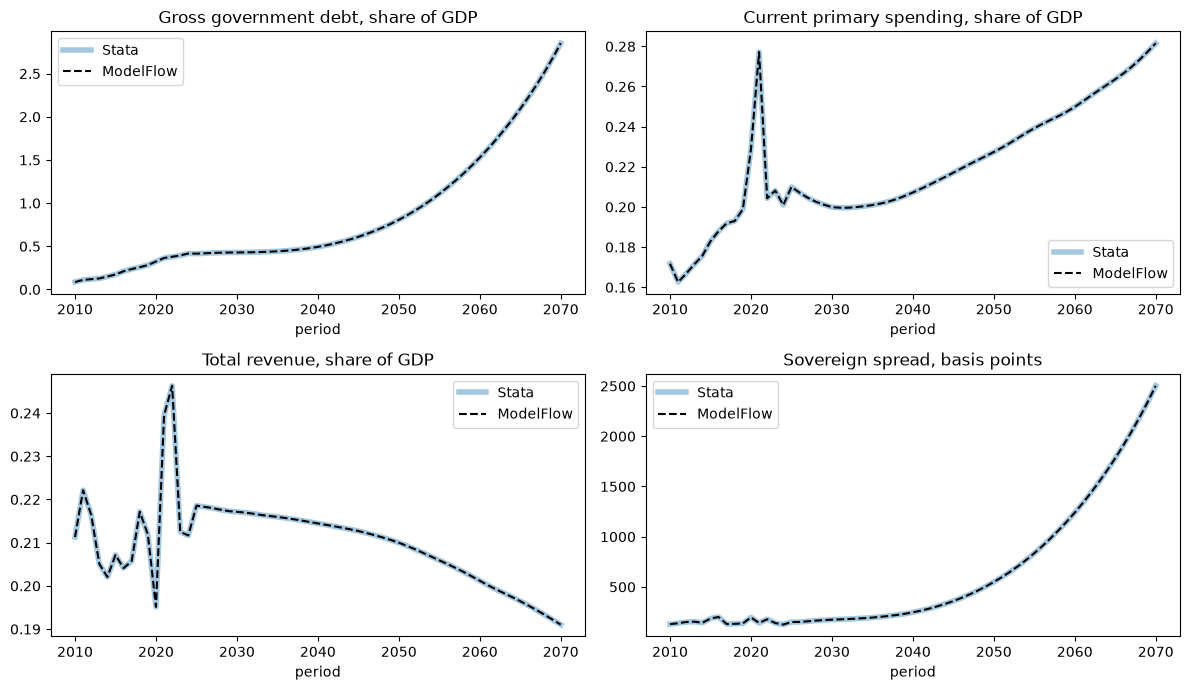

In [22]:
import matplotlib.pyplot as plt
from pathlib import Path

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, v in zip(axes.flat, ['b_g', 'g', 'rev_tot', 'embi']):
    STATA.loc[2010:LAST, v].plot(ax=ax, label='Stata', lw=4, alpha=0.4)
    res.loc[2010:LAST, v.upper()].plot(ax=ax, label='ModelFlow', ls='--', color='black')
    ax.set_title(var_description.get(v.upper(), v))
    ax.legend()
fig.tight_layout()

Path('graph').mkdir(exist_ok=True)          # shown in the summary at the top
fig.savefig('graph/stata_vs_modelflow.png', dpi=110)

## Saving the model and data for scenario use

In [23]:
mchile.modeldump('data/chilepens')

## Conclusion

The ModelFlow model reproduces `model_macrofiscal_deterministic.do`. Every compared variable agrees
with `Data_efter.xlsx` to Stata's storage precision, and the estimated coefficients match the
do-file's. The exceptions are the four series the Excel export rounded to two significant digits;
for those ModelFlow matches the file's own components.

**This relies on the corrected `Estimate_ols`.** Before the fix, terms without a coefficient were
not moved to the left-hand side, so the consumption-rate equation was estimated as if the imposed
IMF terms were absent (slopes −0.905 / −0.514 / 0.418 instead of 3.93 / −0.69 / 1.16). The earlier
notebook in `../pensionsmodel/fromzip` was estimated with that version.

What this check does **not** cover:

- **Scenario branches.** Only the shipped settings are reproduced. The retirement-age branches
  (`ret_age = 1–3`) are not in this model; note the do-file's `old_age_dep` for those branches
  counts women twice in the denominator (`n_f_1564 + n_f_1564`), and the stochastic file has the
  correct `n_m_*` terms.
- **2071–2075.** The demographic projections stop in 2070, so Stata's values for those years are
  missing and the comparison stops at 2070.

## Writing the model documentation

In [ ]:
# the equations block by block with the estimation results - a chapter of the book
head = '''# Model documentation

:::{note}
This chapter is generated by the [loading notebook](chile_macrofiscal_deterministic.ipynb) from
the model itself: the equations, the text written with them and the estimation results
(`chile.markdown_with_estimation`). It can serve as the paper presenting the model, and because it
is generated, paper and model are always in sync: when the model changes, rerunning the loading
notebook updates the paper.
:::

'''
Path('model_documentation.md').write_text(head + chile.markdown_with_estimation, encoding='utf-8')